### Learn Pandas in 10 minutes

[https://pandas.pydata.org/pandas-docs/stable/10min.html](https://pandas.pydata.org/pandas-docs/stable/10min.html)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Датасет
Мы будем работать с датасетом задержек авиарейсов https://www.kaggle.com/datasets/usdot/flight-delays. Скачайте файлы из этого датасета.

### Чтение данных

`pd.read_csv` считает таблицу в объект типа датафрейм.
При чтении таблицы возникает некий Warning - про него поговорим чуть позже.

`df.head` покажет пять (по умолчанию) верхних строк таблицы:

In [ ]:
df = pd.read_csv('flights/flights.csv')
df.head()

C:\Users\E.Illarionov\AppData\Local\Continuum\anaconda3\lib\site-packages\IPython\core\interactiveshell.py:2785: DtypeWarning: Columns (7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Из чего состоит таблица

![](https://media.geeksforgeeks.org/wp-content/cdn-uploads/creating_dataframe1.png)

Индексация строк/столбцов

![](https://i0.wp.com/sparkbyexamples.com/wp-content/uploads/2021/10/pandas-difference-loc-vs-iloc.png?resize=840%2C353&ssl=1)

Размеры таблицы

In [ ]:
len(df), df.shape

(5819079, (5819079, 31))

Список названий колонок

In [ ]:
df.columns

Index(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER',
       'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
       'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
       'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE',
       'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME',
       'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON',
       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY',
       'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY'],
      dtype='object')

Базовая информация по колонкам

In [ ]:
print(df.info(null_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   YEAR                 5819079 non-null  int64  
 1   MONTH                5819079 non-null  int64  
 2   DAY                  5819079 non-null  int64  
 3   DAY_OF_WEEK          5819079 non-null  int64  
 4   AIRLINE              5819079 non-null  object 
 5   FLIGHT_NUMBER        5819079 non-null  int64  
 6   TAIL_NUMBER          5804358 non-null  object 
 7   ORIGIN_AIRPORT       5819079 non-null  object 
 8   DESTINATION_AIRPORT  5819079 non-null  object 
 9   SCHEDULED_DEPARTURE  5819079 non-null  int64  
 10  DEPARTURE_TIME       5732926 non-null  float64
 11  DEPARTURE_DELAY      5732926 non-null  float64
 12  TAXI_OUT             5730032 non-null  float64
 13  WHEELS_OFF           5730032 non-null  float64
 14  SCHEDULED_TIME       5819073 non-null  float64
 15

Пришло время вспомнить про warning, который возникал при чтении таблицы. Он связан с тем, что данные в таблицы неоднородны по типу. Как одно из побочных явлений - обратите внимание на колонки, в которых по смыслу стоит время. Они при чтении преобразовались в тип float. В результате запись 0005 превратилась в число 5. Чтобы избежать таких проблем, будем считывать данные как строковые переменные:

In [ ]:
df = pd.read_csv('flights/flights.csv', dtype=str)
df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,...,0408,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,...,0741,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,...,0811,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,...,0756,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,...,0259,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Определим колонки с пропущенными значениями

In [ ]:
df.isna().any(axis=0)

YEAR                   False
MONTH                  False
DAY                    False
DAY_OF_WEEK            False
AIRLINE                False
FLIGHT_NUMBER          False
TAIL_NUMBER             True
ORIGIN_AIRPORT         False
DESTINATION_AIRPORT    False
SCHEDULED_DEPARTURE    False
DEPARTURE_TIME          True
DEPARTURE_DELAY         True
TAXI_OUT                True
WHEELS_OFF              True
SCHEDULED_TIME          True
ELAPSED_TIME            True
AIR_TIME                True
DISTANCE               False
WHEELS_ON               True
TAXI_IN                 True
SCHEDULED_ARRIVAL      False
ARRIVAL_TIME            True
ARRIVAL_DELAY           True
DIVERTED               False
CANCELLED              False
CANCELLATION_REASON     True
AIR_SYSTEM_DELAY        True
SECURITY_DELAY          True
AIRLINE_DELAY           True
LATE_AIRCRAFT_DELAY     True
WEATHER_DELAY           True
dtype: bool

Найдем строки, для которых не указано время отправления или прибытия

In [ ]:
df[['DEPARTURE_TIME', 'ARRIVAL_TIME']].isna().any(axis=1)

0          False
1          False
2          False
3          False
4          False
           ...  
5819074    False
5819075    False
5819076    False
5819077    False
5819078    False
Length: 5819079, dtype: bool

Найдем количество таких строк

In [ ]:
df[['DEPARTURE_TIME', 'ARRIVAL_TIME']].isna().any(axis=1).sum()

92513

и выбросим их

In [ ]:
df = df.loc[~df[['DEPARTURE_TIME', 'ARRIVAL_TIME']].isna().any(axis=1)]

Пример подсчета уникальных элементов в столбце

In [ ]:
df['AIRLINE'].value_counts()
df.AIRLINE.value_counts()

WN    1245053
DL     871946
AA     714855
OO     577943
EV     556425
UA     508916
MQ     279431
B6     262687
US     194586
AS     171692
NK     115343
F9      90231
HA      76093
VX      61365
Name: AIRLINE, dtype: int64

Плохой пример построения гистограмм по значениям в столбце

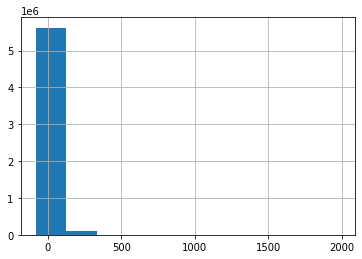

In [ ]:
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

df.DEPARTURE_DELAY = df.DEPARTURE_DELAY.astype(float)
df.DEPARTURE_DELAY.hist()
plt.show()

Более показательный график

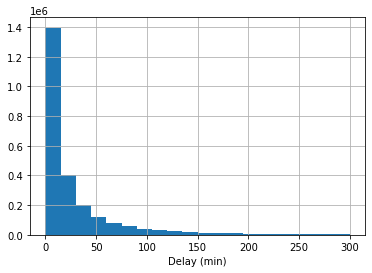

In [ ]:
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

df.DEPARTURE_DELAY.hist(bins=20, range=(0, 300))
plt.xlabel('Delay (min)')
plt.show()

Базовые статистики

In [ ]:
df.loc[df.DEPARTURE_DELAY > 0, 'DEPARTURE_DELAY'].mean()

28.655498471292017

In [ ]:
df.loc[df.DEPARTURE_DELAY > 0, 'DEPARTURE_DELAY'].std()

52.97401649681914

In [ ]:
df.loc[df.DEPARTURE_DELAY > 0, 'DEPARTURE_DELAY'].median()

15.0

Создание колонки с датой, вместо трех отдельных колонок

In [ ]:
pd.to_datetime(df[['YEAR', 'MONTH', 'DAY']])

0         2015-01-01
1         2015-01-01
2         2015-01-01
3         2015-01-01
4         2015-01-01
             ...    
5819074   2015-12-31
5819075   2015-12-31
5819076   2015-12-31
5819077   2015-12-31
5819078   2015-12-31
Length: 5726566, dtype: datetime64[ns]

Создание новой колонки в таблице

In [ ]:
df['DATE'] = pd.to_datetime(df[['YEAR', 'MONTH', 'DAY']])
df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DATE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,...,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,...,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,...,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01


Пример использования:

In [ ]:
df.loc[df.DATE <= pd.to_datetime('2015-02-14')]

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DATE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,...,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,...,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,...,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
681023,2015,2,14,6,B6,1503,N547JB,JFK,SJU,2359,...,45,0,0,NaN,45,0,0,0,0,2015-02-14
681024,2015,2,14,6,US,1770,N825AW,SLC,PHL,2359,...,-13,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-02-14
681025,2015,2,14,6,US,467,N642AW,PHX,MSP,2359,...,86,0,0,NaN,0,0,86,0,0,2015-02-14
681026,2015,2,14,6,F9,300,N204FR,DEN,TPA,2359,...,-16,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-02-14


Удалим ненужные более столбцы

In [ ]:
df = df.drop(columns=['YEAR', 'MONTH', 'DAY'])
df.head()

,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DATE
0,4,AS,98,N407AS,ANC,SEA,0005,2354,-11.0,21,...,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
1,4,AA,2336,N3KUAA,LAX,PBI,0010,0002,-8.0,12,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
2,4,US,840,N171US,SFO,CLT,0020,0018,-2.0,16,...,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
3,4,AA,258,N3HYAA,LAX,MIA,0020,0015,-5.0,15,...,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01
4,4,AS,135,N527AS,SEA,ANC,0025,0024,-1.0,11,...,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-01


Как поменять порядок столбцов?

In [ ]:
cols = list(df.columns)
cols[-1:] + cols[:-1]

['DATE',
 'DAY_OF_WEEK',
 'AIRLINE',
 'FLIGHT_NUMBER',
 'TAIL_NUMBER',
 'ORIGIN_AIRPORT',
 'DESTINATION_AIRPORT',
 'SCHEDULED_DEPARTURE',
 'DEPARTURE_TIME',
 'DEPARTURE_DELAY',
 'TAXI_OUT',
 'WHEELS_OFF',
 'SCHEDULED_TIME',
 'ELAPSED_TIME',
 'AIR_TIME',
 'DISTANCE',
 'WHEELS_ON',
 'TAXI_IN',
 'SCHEDULED_ARRIVAL',
 'ARRIVAL_TIME',
 'ARRIVAL_DELAY',
 'DIVERTED',
 'CANCELLED',
 'CANCELLATION_REASON',
 'AIR_SYSTEM_DELAY',
 'SECURITY_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY']

Переместим последний столбец на первое место

In [ ]:
df = df[cols[-1:] + cols[:-1]]
df.head()

,DATE,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015-01-01,4,AS,98,N407AS,ANC,SEA,0005,2354,-11.0,...,0408,-22,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-01,4,AA,2336,N3KUAA,LAX,PBI,0010,0002,-8.0,...,0741,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015-01-01,4,US,840,N171US,SFO,CLT,0020,0018,-2.0,...,0811,5,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015-01-01,4,AA,258,N3HYAA,LAX,MIA,0020,0015,-5.0,...,0756,-9,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015-01-01,4,AS,135,N527AS,SEA,ANC,0025,0024,-1.0,...,0259,-21,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Посмотрим на столбец ORIGIN_AIRPORT. В нем много непонятных значений

In [ ]:
df.ORIGIN_AIRPORT.unique()

array(['ANC', 'LAX', 'SFO', 'SEA', 'LAS', 'DEN', 'SLC', 'PDX', 'FAI',
       'MSP', 'PHX', 'SJU', 'PBG', 'IAG', 'PSE', 'BQN', 'ORD', 'GEG',
       'HNL', 'ONT', 'MCO', 'BOS', 'HIB', 'ABR', 'DFW', 'MKE', 'IAH',
       'BNA', 'BRO', 'VPS', 'BOI', 'BJI', 'PHL', 'SBN', 'EUG', 'IAD',
       'BUF', 'PWM', 'JFK', 'CRP', 'PIA', 'FAT', 'SMF', 'AUS', 'MCI',
       'ATL', 'JAX', 'MFR', 'IDA', 'MSN', 'DCA', 'SAT', 'CHS', 'SBA',
       'IND', 'CLE', 'GSP', 'BDL', 'RIC', 'BFL', 'OMA', 'RDM', 'FLL',
       'CID', 'TPA', 'SYR', 'ROC', 'TYR', 'LAN', 'GSO', 'EWR', 'PBI',
       'RSW', 'OAK', 'PVD', 'RNO', 'PIT', 'ABQ', 'MIA', 'BWI', 'TUL',
       'LGA', 'LIT', 'MSY', 'OKC', 'ATW', 'PNS', 'MEM', 'TYS', 'MHT',
       'SAV', 'CLT', 'GRB', 'ABE', 'JAN', 'OAJ', 'FAR', 'ERI', 'LEX',
       'CWA', 'TTN', 'RDU', 'CVG', 'BHM', 'ACY', 'DTW', 'RAP', 'TUS',
       'EAU', 'DLH', 'FSD', 'INL', 'SPI', 'CLD', 'COD', 'CMH', 'PSC',
       'CPR', 'ACV', 'DAL', 'PAH', 'MRY', 'ESC', 'ISN', 'PSP', 'CAE',
       'STL', 'BTV',

Как отделить нормальные значения от ненормальных? Например, по длине строки:

In [ ]:
df.ORIGIN_AIRPORT.apply(len)

0          3
1          3
2          3
3          3
4          3
          ..
5819074    3
5819075    3
5819076    3
5819077    3
5819078    3
Name: ORIGIN_AIRPORT, Length: 5726566, dtype: int64

Фильтруем датасет (комментарий: на практике не нужно доверять признаку длина строки, лучше непосредственно проверять, если ли данная запись в справочнике аэропортов)

In [ ]:
df = df.loc[(df.ORIGIN_AIRPORT.apply(len) == 3) &
            (df.DESTINATION_AIRPORT.apply(len) == 3)]

In [ ]:
df.AIRLINE.unique()

array(['AS', 'AA', 'US', 'DL', 'NK', 'UA', 'HA', 'B6', 'OO', 'EV', 'F9',
       'WN', 'MQ', 'VX'], dtype=object)

Метод loc позволяет получать срезы датасета. Например, найдем из каких городов летает авиакомпание АА:

In [ ]:
df.loc[df.AIRLINE == 'AA', 'ORIGIN_AIRPORT'].unique()

array(['LAX', 'SFO', 'LAS', 'SEA', 'DEN', 'PHX', 'MCO', 'DFW', 'BOS',
       'IAH', 'SAT', 'JFK', 'AUS', 'EWR', 'MIA', 'SLC', 'BWI', 'MCI',
       'TUL', 'LGA', 'LIT', 'PDX', 'TPA', 'SMF', 'MSY', 'OMA', 'OKC',
       'DCA', 'STL', 'SJU', 'MKE', 'BNA', 'MSP', 'SAN', 'RDU', 'IAD',
       'CLT', 'PHL', 'PBI', 'JAX', 'PIT', 'COS', 'DSM', 'RIC', 'BDL',
       'SNA', 'BHM', 'MEM', 'CLE', 'ATL', 'FAT', 'DAY', 'ORF', 'IND',
       'CMH', 'ELP', 'ONT', 'RNO', 'SJC', 'ABQ', 'PSP', 'RSW', 'FLL',
       'JAC', 'TUS', 'HNL', 'ORD', 'EGE', 'DTW', 'STT', 'MFE', 'STX',
       'HDN', 'ICT', 'KOA', 'HOU', 'OGG', 'GUC', 'LIH', 'SDF', 'MTJ',
       'PNS', 'LBB', 'XNA', 'ANC', 'OAK', 'PVD', 'BUF', 'BOI', 'ALB',
       'PWM', 'SYR', 'GEG', 'GSO', 'CHS', 'ILM', 'ROC', 'MDT'],
      dtype=object)

Также легко найти из каких городов АА делает наибольшее число рейсов

In [ ]:
df.loc[df.AIRLINE == 'AA', 'ORIGIN_AIRPORT'].value_counts()

DFW    131464
ORD     49688
MIA     47792
CLT     41512
LAX     32409
        ...  
GUC       113
MDT        49
MTJ        29
XNA        18
LIT         9
Name: ORIGIN_AIRPORT, Length: 98, dtype: int64

Иногда вместо таблиц удобно смотреть на графики. У датафрейма и серии есть встроенный метод plot

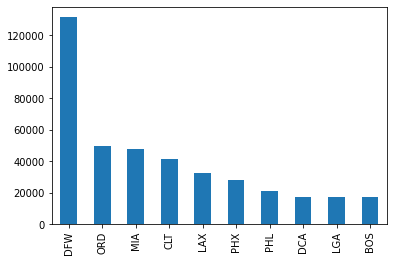

In [ ]:
fig = plt.figure()
fig.patch.set_facecolor('xkcd:white')

df.loc[df.AIRLINE == 'AA', 'ORIGIN_AIRPORT'].value_counts()[:10].plot(kind='bar')
plt.show()

Еще один способ как найти перевозчика с наибольшим числом рейсов. Методом groupby

In [ ]:
df.groupby('AIRLINE').size().sort_values()[::-1]

AIRLINE
WN    1140890
DL     796418
AA     638313
OO     529394
EV     511186
UA     463158
MQ     257726
B6     240906
US     194586
AS     157268
NK     105198
F9      82142
HA      69863
VX      55924
dtype: int64

Найдем, сколько времени самолеты каждой авиакомпании проводят в воздухе. Обратите внимание, что сначала строковые значения нужно привести в числовой тип:

In [ ]:
df.AIR_TIME = df.AIR_TIME.astype(float)
df.groupby('AIRLINE')['AIR_TIME'].sum()

AIRLINE
AA     89473152.0
AS     24786823.0
B6     34637886.0
DL     92137719.0
EV     37151025.0
F9     10691374.0
HA      5931683.0
MQ     17292639.0
NK     13905437.0
OO     39974767.0
UA     76413094.0
US     24428249.0
VX     10214217.0
WN    117560358.0
Name: AIR_TIME, dtype: float64

Найдем авиакомпанию, у которой больше всего география вылетов (как еще можно решить эту задачу?)

In [ ]:
df.groupby('AIRLINE')['ORIGIN_AIRPORT'].nunique().sort_values()[::-1]

AIRLINE
OO    211
EV    181
DL    156
MQ    133
AA     98
UA     94
WN     86
US     79
AS     67
B6     64
F9     63
NK     34
VX     21
HA     17
Name: ORIGIN_AIRPORT, dtype: int64

У какой авиакомпании больше всего маршрутов?

In [ ]:
df['ROUTE'] = df['ORIGIN_AIRPORT'] + df['DESTINATION_AIRPORT']
df.groupby('AIRLINE')['ROUTE'].nunique().sort_values()[::-1]

AIRLINE
EV    1381
WN    1333
OO    1322
DL     963
AA     707
UA     702
MQ     428
B6     341
US     340
F9     333
NK     316
AS     251
VX      71
HA      56
Name: ROUTE, dtype: int64

Пора заменить кодовые названия авиакомпаний и аэропортов на полные названия. Для этого нужно соединять таблицы из датасета. Есть как минимум 4 способа это сделать:

![](https://www.tektutorialshub.com/wp-content/uploads/2019/12/Differences-in-inner-and-left-right-and-full-outer-joins.png)

Таблица перевозчиков

In [ ]:
df_air = pd.read_csv('flights/airlines.csv')
df_air.head()

,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways


Подготовим левую таблицу

In [ ]:
tmp = df.groupby('AIRLINE')['ROUTE'].nunique().sort_values()[::-1].to_frame().reset_index()
tmp.head()

,AIRLINE,ROUTE
0,EV,1381
1,WN,1333
2,OO,1322
3,DL,963
4,AA,707


Сделаем одно необязательное действие по переименованию колонок

In [ ]:
tmp = tmp.rename(columns={'AIRLINE': 'IATA_CODE'})
tmp.head()

,IATA_CODE,ROUTE
0,EV,1381
1,WN,1333
2,OO,1322
3,DL,963
4,AA,707


Соединим две таблицы по ключу IATA_CODE

In [ ]:
tmp.merge(df_air, on='IATA_CODE')

,IATA_CODE,ROUTE,AIRLINE
0,EV,1381,Atlantic Southeast Airlines
1,WN,1333,Southwest Airlines Co.
2,OO,1322,Skywest Airlines Inc.
3,DL,963,Delta Air Lines Inc.
4,AA,707,American Airlines Inc.
5,UA,702,United Air Lines Inc.
6,MQ,428,American Eagle Airlines Inc.
7,B6,341,JetBlue Airways
8,US,340,US Airways Inc.
9,F9,333,Frontier Airlines Inc.


Теперь поработаем с аэропортами и изобразим на георгрфической карты все маршруты одной из компаний

Считаем таблицу аэропортов

In [ ]:
df_arp = pd.read_csv('flights/airports.csv')
df_arp.head()

,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447


Нам потребуется библиотека basemap. Скорее всего, ее придется установить с помощью команды pip install basemap в терминале или в ячейке ноутбука

In [ ]:
# !pip install basemap

Отрисуем карту

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


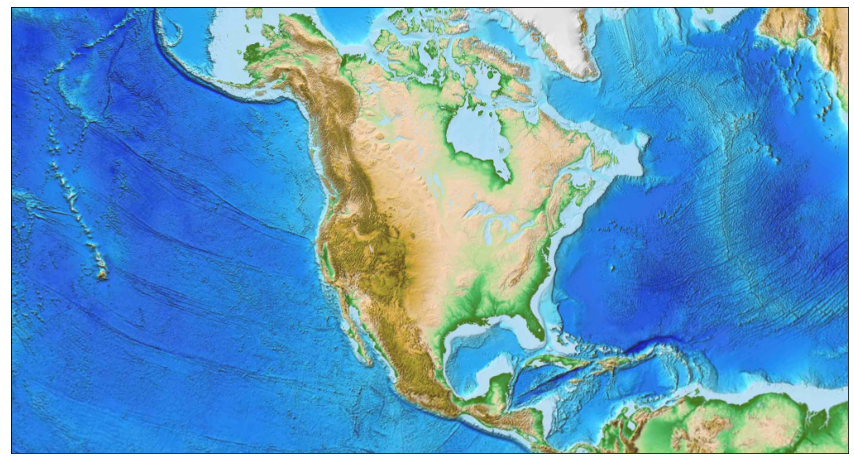

In [ ]:
from mpl_toolkits.basemap import Basemap

fig = plt.figure(figsize=(15, 10))
land = Basemap(projection='lcc', resolution=None,
               width=15E6, height=8E6,
               lat_0=45, lon_0=-100,)
land.etopo(scale=0.5, alpha=0.9)
plt.show()

Теперь выберем одного перевозчика и все его маршруты:

In [ ]:
routes = df.loc[df.AIRLINE == 'AA', ['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']].drop_duplicates()
routes

,ORIGIN_AIRPORT,DESTINATION_AIRPORT
1,LAX,PBI
3,LAX,MIA
8,SFO,DFW
11,LAS,MIA
21,SEA,MIA
...,...,...
5726511,PIT,LGA
5757731,PIT,DCA
5799339,MIA,OKC
5802350,OKC,MIA


Нам нужно создать два массива с координатами городом вылета и приземления

In [ ]:
orig = routes[['ORIGIN_AIRPORT']].merge(df_arp,
                                        left_on='ORIGIN_AIRPORT',
                                        right_on='IATA_CODE',
                                        how='left')
dest = routes[['DESTINATION_AIRPORT']].merge(df_arp,
                                             left_on='DESTINATION_AIRPORT',
                                             right_on='IATA_CODE',
                                             how='left')
orig

,ORIGIN_AIRPORT,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,LAX,LAX,Los Angeles International Airport,Los Angeles,CA,USA,33.94254,-118.40807
1,LAX,LAX,Los Angeles International Airport,Los Angeles,CA,USA,33.94254,-118.40807
2,SFO,SFO,San Francisco International Airport,San Francisco,CA,USA,37.61900,-122.37484
3,LAS,LAS,McCarran International Airport,Las Vegas,NV,USA,36.08036,-115.15233
4,SEA,SEA,Seattle-Tacoma International Airport,Seattle,WA,USA,47.44898,-122.30931
...,...,...,...,...,...,...,...,...
702,PIT,PIT,Pittsburgh International Airport,Pittsburgh,PA,USA,40.49147,-80.23287
703,PIT,PIT,Pittsburgh International Airport,Pittsburgh,PA,USA,40.49147,-80.23287
704,MIA,MIA,Miami International Airport,Miami,FL,USA,25.79325,-80.29056
705,OKC,OKC,Will Rogers World Airport,Oklahoma City,OK,USA,35.39309,-97.60073


Чтобы нанести точку с заданной широтой/долготой на карту, георгафические координаты нужно перевести в x, y. Технически, это делается так:
```python
x, y = land(long, lat)```

Практически, это можно реализовать несколькоми способами. Ниже показано два варианта:

In [ ]:
orig_xy = orig[['LONGITUDE', 'LATITUDE']].apply(lambda x: land(*x), axis=1).values
orig_xy = np.stack(orig_xy) #делаем из списка пар координат двумерный массив:
orig_xy

array([[5786464.99178486, 2958583.93375446],
       [5786464.99178486, 2958583.93375446],
       [5538647.58540078, 3449593.3008072 ],
       ...,
       [9558018.51602923, 2077700.43248837],
       [7720388.64285604, 2930177.5528791 ],
       [9472881.97316282, 3596529.37658913]])

А можно было сделать так

In [ ]:
dest_xy = np.array(land(dest['LONGITUDE'], dest['LATITUDE'])).T
dest_xy

array([[9552679.3182904 , 2183543.73257896],
       [9558018.51602923, 2077700.43248837],
       [7782457.61482448, 2649616.19503876],
       ...,
       [7720388.64285604, 2930177.5528791 ],
       [9558018.51602923, 2077700.43248837],
       [9160066.05182196, 3701665.37842076]])

Отрисуем линии на карте:

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


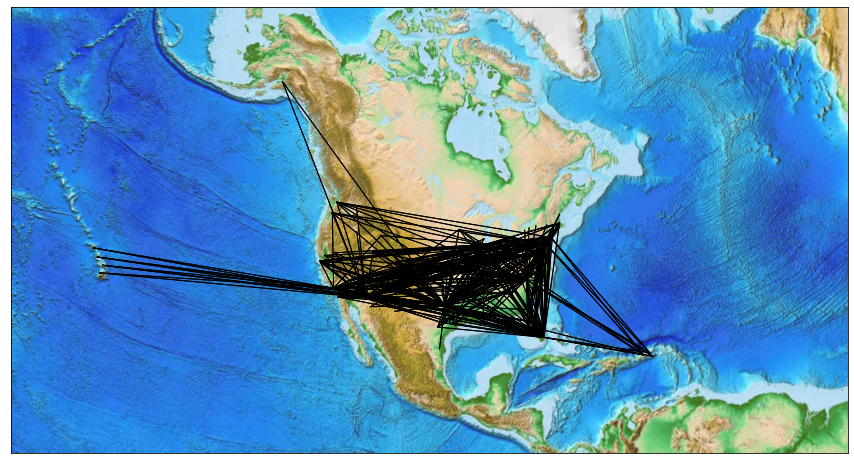

In [ ]:
fig = plt.figure(figsize=(15, 10))
m = Basemap(projection='lcc', resolution=None,
            width=15E6, height=8E6,
            lat_0=45, lon_0=-100,)
m.etopo(scale=0.5, alpha=0.9)

for a, b in zip(orig_xy, dest_xy):
    plt.plot([a[0], b[0]], [a[1], b[1]], c='k', lw=1)
plt.show()

Домашнее задание - подготовить отчет для министерства транспорта, раскрывающий характер и особенности задержек авиарейсов. Отчет должен помочь увидеть проблемные точки и способствовать принятию решений. Поэтому стремитесь не констатировать общие факты, а показывать проблемы. Например, сам по себе факт "средняя задержка вылета составляет 15 минут" мало о чем говорит и не помогает понять, из-за чего так происходит. Напротив, график, показывающий, что по понедельникам опоздания возрастают в три раза по сравнению с остальными днями на фоне возрастания числа рейсов и пассажиров, подсказывает возможную причину проблемы: аэропорты не справляются с неравномерной нагрузкой.

Отчет должен быть оформлен в виде ноутбука с четкой структурой. Вначале в ячейке Markdown идет краткое описание исследуемого вопроса (что будем изучать), затем код и все его выводы (таблицы, графики, величины), после этого снова в ячейке Markdown в которой сформулирован ваш краткий вывод.

В отчете должно быть не менее 5 результатов, подтвержденных графиками. Для разнообразия материала используйте различные типы диаграмм. Все графики должны быть снабжены необходимыми подписями (обозначения осей, заголовок, легенда цветовая схема).

Для решения задач используйте методы библиотеки pandas.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
from uuid import uuid4
from zipfile import BadZipFile, ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/usdot/flight-delays'
DATA_ARCHIVE = Path('usdot-flights.zip')

def ensure_archive():
    if DATA_ARCHIVE.is_file():
        return DATA_ARCHIVE
    pending = DATA_ARCHIVE.with_suffix(f'.{uuid4().hex}.part')
    print('Загружаем датасет Kaggle (около 200 МБ)…')
    try:
        urlretrieve(DATA_URL, pending)
        with ZipFile(pending) as archive:
            if not {'flights.csv', 'airports.csv'}.issubset(archive.namelist()):
                raise ValueError('В архиве отсутствуют таблицы с данными.')
        pending.replace(DATA_ARCHIVE)
    except (OSError, BadZipFile, ValueError) as exc:
        raise RuntimeError(
            'Не удалось загрузить датасет. Скачайте архив по ссылке в отчёте '
            'и положите его в рабочую папку под именем usdot-flights.zip.'
        ) from exc
    finally:
        pending.unlink(missing_ok=True)
    return DATA_ARCHIVE

def read_source(name, **kwargs):
    for path in (Path('flights') / name, Path(name)):
        if path.is_file():
            return pd.read_csv(path, **kwargs)
    with ZipFile(ensure_archive()) as archive, archive.open(name) as file:
        return pd.read_csv(file, **kwargs)

causes = {
    'AIR_SYSTEM_DELAY': 'Авиационная система',
    'SECURITY_DELAY': 'Безопасность',
    'AIRLINE_DELAY': 'Перевозчик',
    'LATE_AIRCRAFT_DELAY': 'Позднее прибытие борта',
    'WEATHER_DELAY': 'Погода',
}
types = dict.fromkeys(['ARRIVAL_DELAY', 'DEPARTURE_DELAY', *causes], 'float32')
keys = ['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']
types.update(dict.fromkeys(keys, 'category'))
columns = ['MONTH', 'DAY_OF_WEEK', 'SCHEDULED_DEPARTURE', 'CANCELLED', 'DIVERTED']
flights = read_source('flights.csv', usecols=columns + list(types), dtype=types)
cancelled = flights['CANCELLED'].eq(1)
diverted = flights['CANCELLED'].eq(0) & flights['DIVERTED'].eq(1)
arrivals = flights.loc[flights['CANCELLED'].eq(0) & flights['DIVERTED'].eq(0)
                       & flights['ARRIVAL_DELAY'].notna()].copy()
arrivals['late'] = arrivals['ARRIVAL_DELAY'].ge(15)
baseline = 100 * arrivals['late'].mean()
display(pd.Series({
    'Всего записей': len(flights),
    'Отмены': cancelled.sum(),
    'Перенаправления среди неотменённых': diverted.sum(),
    'Прибытия с известной задержкой': len(arrivals),
    'Задержки прибытия ≥15 минут': arrivals['late'].sum(),
    'Остальные записи вне выборки прибытий': (
        len(flights) - len(arrivals) - cancelled.sum() - diverted.sum()),
}, name='Число рейсов').to_frame())

BLUE, TEAL, RED, GRAY = '#60a5fa', '#2dd4bf', '#fb923c', '#a8b3c5'
MONTHS = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
          'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
DAYS = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
plt.style.use('dark_background')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#151515',
    'axes.facecolor': '#151515',
    'savefig.facecolor': '#151515',
    'text.color': 'white',
    'axes.titlecolor': 'white',
    'axes.labelcolor': 'white',
    'xtick.color': 'white',
    'ytick.color': 'white',
    'legend.labelcolor': 'white',
    'font.family': ['Times New Roman', 'DejaVu Serif'],
    'mathtext.default': 'regular',
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.axisbelow': True,
})
finding = (f'В анализ прибытий вошло {len(arrivals)/len(flights):.1%} записей. '
           f'Из них {baseline:.1f}% рейсов прибыли с задержкой ≥15 минут.')

,Число рейсов
Всего записей,5819079
Отмены,89884
Перенаправления среди неотменённых,15187
Прибытия с известной задержкой,5714008
Задержки прибытия ≥15 минут,1063439
Остальные записи вне выборки прибытий,0


**Вывод.** В анализ прибытий вошло 98,2% записей. Из них 18,6% рейсов прибыли с задержкой ≥15 минут.

### 1. Сезонность. Совпадают ли пики задержек и отмен?

Сравним доли задержек и отмен по месяцам. Каждая панель использует собственный знаменатель и шкалу.

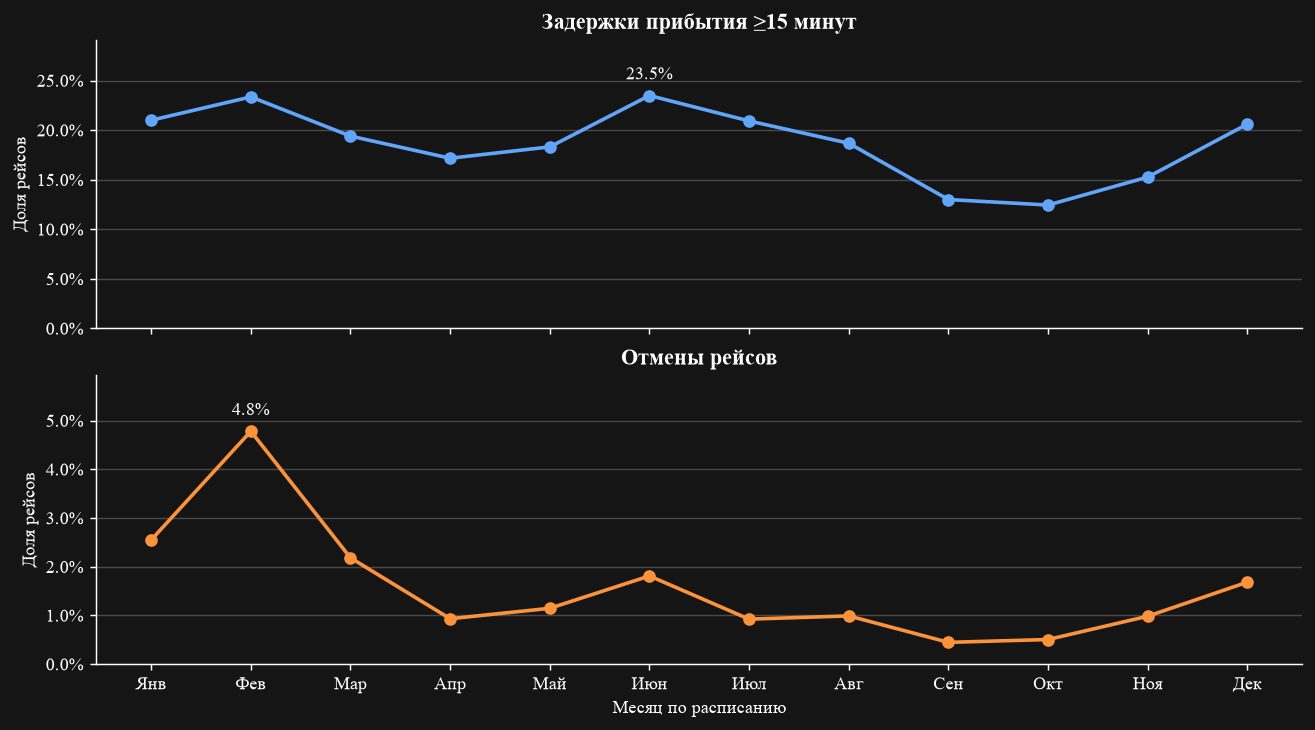

In [ ]:
monthly = 100 * arrivals.groupby('MONTH')['late'].mean()
cancel = 100 * flights.groupby('MONTH')['CANCELLED'].mean()
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 5.5), layout='constrained')
for ax, metric, color, title in zip(
    axes, [monthly, cancel], [BLUE, RED], ['Задержки прибытия ≥15 минут', 'Отмены рейсов']
):
    ax.plot(metric.index, metric, 'o-', color=color, linewidth=2)
    ax.set(title=title, ylabel='Доля рейсов', ylim=(0, metric.max() * 1.24))
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.grid(axis='y', alpha=.22)
    peak = metric.idxmax()
    ax.annotate(f'{metric[peak]:.1f}%', (peak, metric[peak]),
                xytext=(0, 9), textcoords='offset points', ha='center', color='white')
axes[1].set(xticks=range(1, 13), xticklabels=MONTHS, xlabel='Месяц по расписанию')
plt.show()
peak, low, cp = monthly.idxmax(), monthly.idxmin(), cancel.idxmax()
finding = (f'Пик задержек пришёлся на месяц «{MONTHS[peak-1]}» ({monthly[peak]:.1f}%), '
           f'минимум — на «{MONTHS[low-1]}» ({monthly[low]:.1f}%). '
           f'Больше всего отмен по доле было в месяце «{MONTHS[cp-1]}» ({cancel[cp]:.1f}%). '
           'Планы на сезон отмен и сезон задержек следует проверять отдельно.')

**Вывод.** Пик задержек пришёлся на месяц «Июн» (23,5%), минимум — на «Окт» (12,4%). Больше всего отмен по доле было в месяце «Фев» (4,8%).

### 2. Расписание. В какие дни и часы чаще опаздывают?

Группируем по дню недели и местному часу вылета по расписанию. Серым отмечены интервалы с числом наблюдений меньше 1 000. Состав аэропортов и маршрутов меняется по часам.

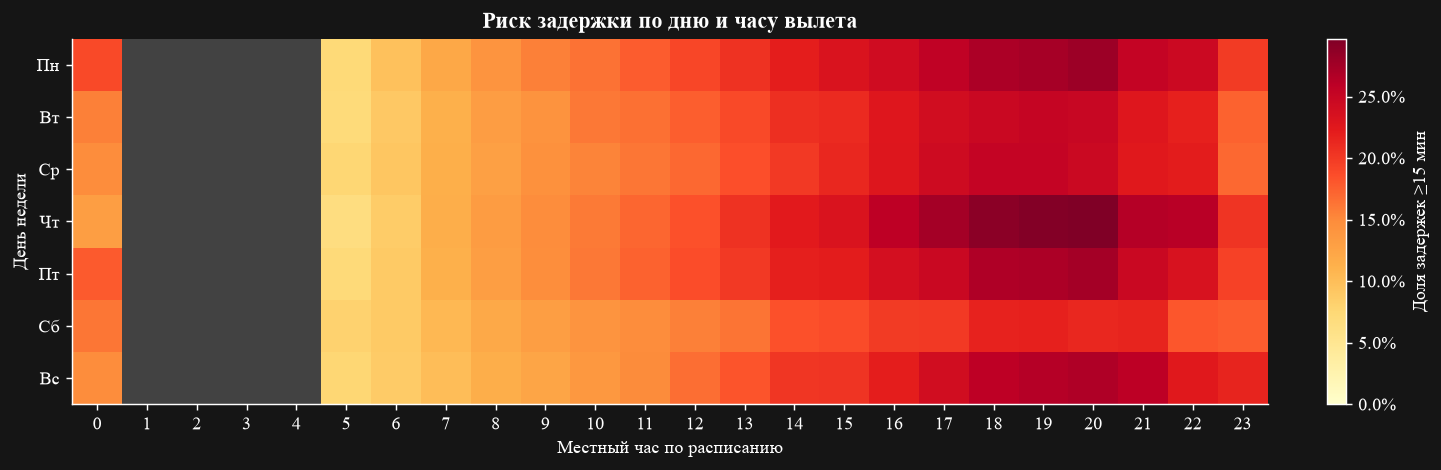

In [ ]:
hhmm = arrivals['SCHEDULED_DEPARTURE']
hour = (hhmm // 100).where(hhmm.between(0, 2359) & (hhmm % 100).lt(60))
slots = arrivals.assign(hour=hour).groupby(['DAY_OF_WEEK', 'hour'])['late'].agg(['size', 'mean'])
eligible = slots.loc[slots['size'].ge(1000)]
grid = (100 * eligible['mean']).unstack().reindex(index=range(1, 8), columns=range(24))
fig, ax = plt.subplots(figsize=(11, 3.5), layout='constrained')
cmap = plt.get_cmap('YlOrRd').copy()
cmap.set_bad('#424242')
image = ax.imshow(grid, aspect='auto', cmap=cmap, vmin=0)
fig.colorbar(image, ax=ax, format=PercentFormatter(), label='Доля задержек ≥15 мин')
ax.set(title='Риск задержки по дню и часу вылета', xlabel='Местный час по расписанию',
       ylabel='День недели', xticks=range(24), yticks=range(7), yticklabels=DAYS)
plt.show()
day, hr = eligible['mean'].idxmax()
row = eligible.loc[(day, hr)]
finding = (f"Среди показанных интервалов максимум — {row['mean']:.1%} "
           f"({DAYS[day-1]}, {int(hr):02d}:00, {int(row['size']):,} прибытий) "
           f"при средней по стране {baseline:.1f}%. "
           "Этот интервал стоит проверить по отдельным аэропортам с учётом нагрузки.")

**Вывод.** Среди показанных интервалов максимум — 29,7% (Чт, 20:00, 38 084 прибытий) при средней по стране 18,6%.

### 3. Тяжесть. Как часто задержка выходит далеко за порог 15 минут?

Распределим задержанные прибытия по длительности. Справа — доля рейсов, достигших каждого порога. В обеих панелях знаменатель — все прибытия с задержкой ≥15 минут.

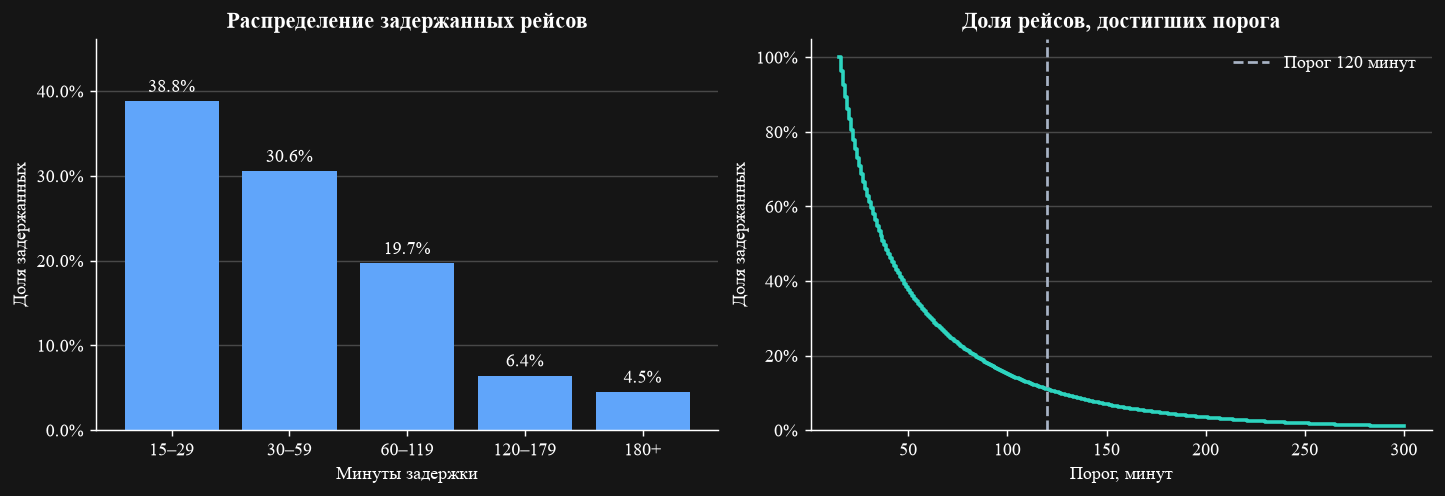

In [ ]:
late = arrivals.loc[arrivals['late']]
delays = late['ARRIVAL_DELAY']
bands = pd.cut(delays, [15, 30, 60, 120, 180, np.inf], right=False)
share = 100 * bands.value_counts(sort=False, normalize=True)
thresholds = np.arange(15, 301)
ordered = np.sort(delays.to_numpy())
tail = 100 * (len(ordered) - np.searchsorted(ordered, thresholds)) / len(ordered)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
bars = left.bar(['15–29', '30–59', '60–119', '120–179', '180+'], share, color=BLUE)
left.bar_label(bars, labels=[f'{v:.1f}%' for v in share], padding=3)
left.set(title='Распределение задержанных рейсов', xlabel='Минуты задержки',
         ylabel='Доля задержанных', ylim=(0, share.max() * 1.19))
right.step(thresholds, tail, where='post', color=TEAL, linewidth=2)
right.axvline(120, color=GRAY, linestyle='--', label='Порог 120 минут')
right.set(title='Доля рейсов, достигших порога', xlabel='Порог, минут',
          ylabel='Доля задержанных', ylim=(0, 105))
right.legend(frameon=False)
for ax in (left, right):
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.grid(axis='y', alpha=.22)
plt.show()
severe = int(delays.ge(120).sum())
finding = (f'{severe:,} рейсов прибыли с опозданием на два часа и более. '
           f'Это {severe / len(late):.1%} задержанных и {severe / len(arrivals):.1%} '
           'всех учтённых прибытий. Этот порог выделяет тяжёлые сбои для отдельного мониторинга.')

**Вывод.** 116 256 рейсов прибыли с опозданием на два часа и более. Это 10,9% задержанных и 2,0% всех учтённых прибытий.

### 4. Маршруты. Где высокий риск сочетается с большим числом задержек?

Сравним направленные пары аэропортов с минимум 1 000 прибытий. Для маршрута оба кода должны присутствовать в справочнике. Записи с несопоставленными кодами, в том числе числовыми, входят в общие показатели, а покрытие маршрутов приведено отдельно.

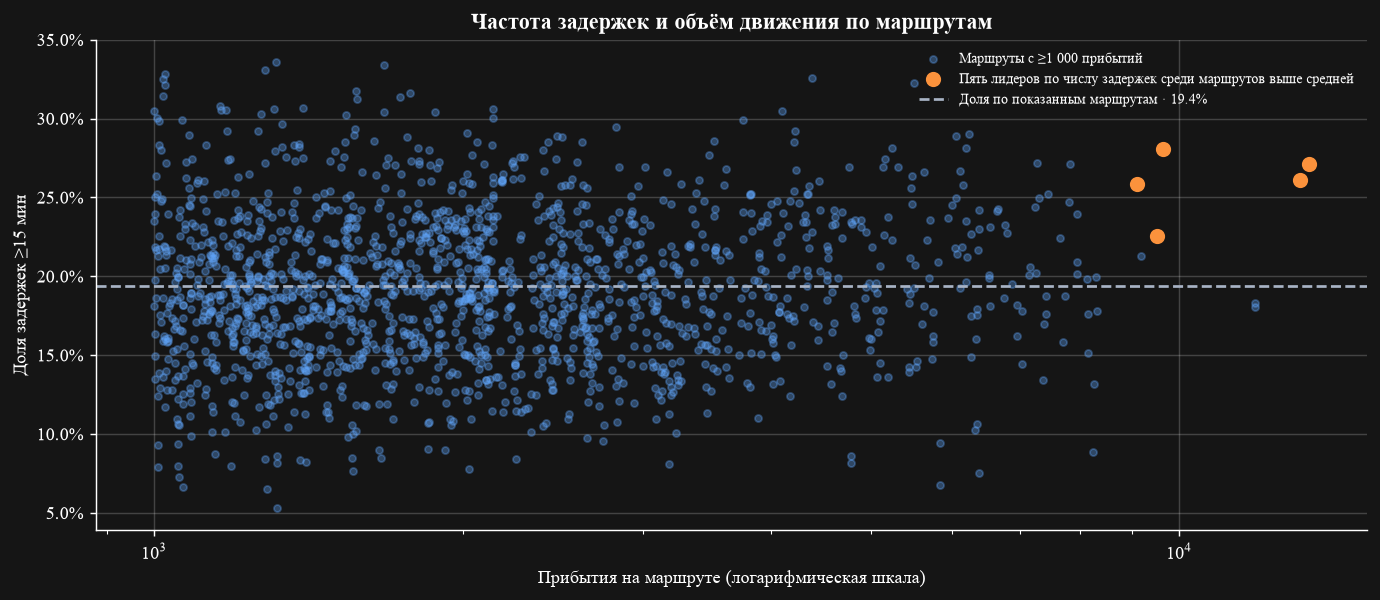

,,Прибытия,Задержки ≥15 мин,"Доля, %"
Вылет,Прибытие,,,
SFO,LAX,13400,3636,27.1
LAX,SFO,13109,3423,26.1
LAS,LAX,9651,2706,28.0
ORD,LGA,9101,2353,25.9
LAX,LAS,9522,2147,22.5


In [ ]:
airports = read_source('airports.csv', usecols=['IATA_CODE'])
known = arrivals[keys[0]].isin(airports['IATA_CODE']) & arrivals[keys[1]].isin(airports['IATA_CODE'])
routes = arrivals.loc[known].groupby(keys, observed=True)['late'].agg(['size', 'sum', 'mean'])
routes = routes.loc[routes['size'].ge(1000)].copy()
routes['rate'] = 100 * routes['mean']
route_baseline = 100 * routes['sum'].sum() / routes['size'].sum()
priority = routes.loc[routes['rate'].gt(route_baseline)].nlargest(5, 'sum')
fig, ax = plt.subplots(figsize=(10.5, 4.5), layout='constrained')
ax.scatter(routes['size'], routes['rate'], s=15, color=BLUE, alpha=.35,
           label='Маршруты с ≥1 000 прибытий')
ax.scatter(priority['size'], priority['rate'], s=55, color=RED,
           label='Пять лидеров по числу задержек среди маршрутов выше средней')
ax.axhline(route_baseline, color=GRAY, linestyle='--',
           label=f'Доля по показанным маршрутам · {route_baseline:.1f}%')
ax.set(xscale='log', xlabel='Прибытия на маршруте (логарифмическая шкала)',
       ylabel='Доля задержек ≥15 мин', title='Частота задержек и объём движения по маршрутам')
ax.yaxis.set_major_formatter(PercentFormatter())
ax.grid(alpha=.2)
ax.legend(frameon=False, loc='upper right', fontsize=8)
plt.show()
display(priority[['size', 'sum', 'rate']].round(1).rename(columns={
    'size': 'Прибытия', 'sum': 'Задержки ≥15 мин', 'rate': 'Доля, %',
}).rename_axis(index=['Вылет', 'Прибытие']))
origin, destination = priority.index[0]
first = priority.iloc[0]
finding = (f"Оба кода сопоставились для {known.mean():.1%} прибытий. "
           f"Среди показанных маршрутов выше средней лидирует {origin} → {destination}: "
           f"{int(first['sum']):,} задержек ({first['rate']:.1f}% прибытий). "
           "Этот маршрут — отправная точка для разбора расписания с аэропортами и перевозчиками.")

**Вывод.** Оба кода сопоставились для 91,5% прибытий. Среди показанных маршрутов выше средней лидирует SFO → LAX: 3 636 задержек (27,1% прибытий).

### 5. Учтённые причины. Что составляет длительные задержки?

Сравним состав зарегистрированных минут для задержек разной тяжести. В выборку входят рейсы, у которых заполнены все пять полей причин и сумма минут положительна. В одном рейсе могут учитываться несколько категорий.

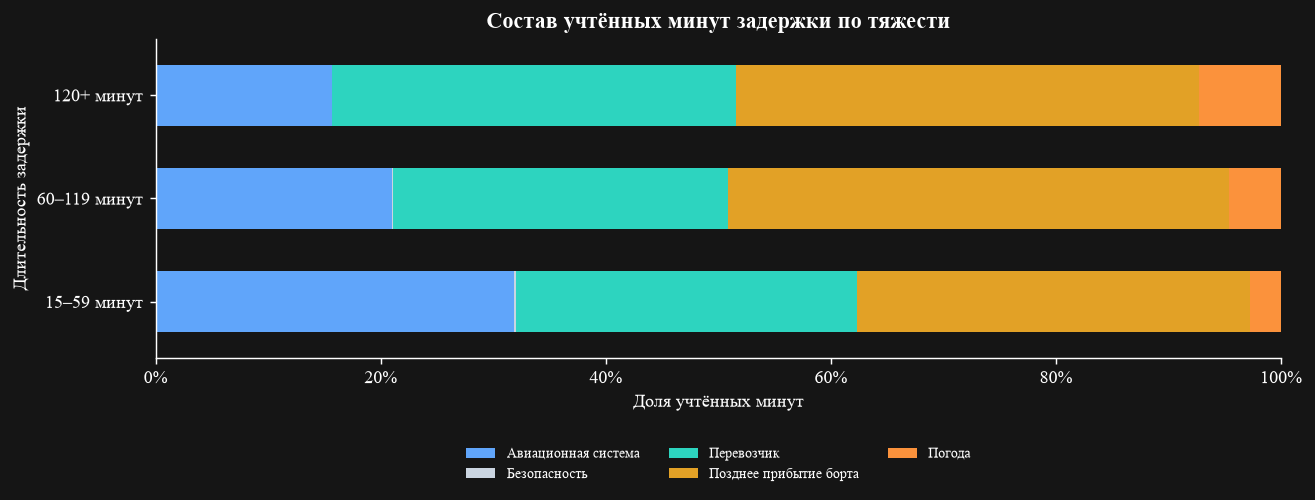

In [ ]:
cause_data = late[list(causes)].dropna()
cause_data = cause_data.loc[cause_data.sum(axis=1).gt(0)]
severity = pd.cut(late.loc[cause_data.index, 'ARRIVAL_DELAY'], [15, 60, 120, np.inf],
                  right=False, labels=['15–59 минут', '60–119 минут', '120+ минут'])
minutes = cause_data.groupby(severity, observed=True).sum().rename(columns=causes)
composition = 100 * minutes.div(minutes.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 3.7), layout='constrained')
composition.plot.barh(stacked=True, ax=ax,
                      color=[BLUE, '#cbd5e1', TEAL, '#e2a126', RED], width=.59)
ax.set(title='Состав учтённых минут задержки по тяжести', xlabel='Доля учтённых минут',
       ylabel='Длительность задержки', xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter())
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(.5, -.24), fontsize=8)
plt.show()
long_causes = composition.loc['120+ минут']
finding = (f'Положительная сумма минут по причинам есть у {len(cause_data)/len(late):.1%} '
           f'задержанных рейсов. Среди задержек от двух часов крупнейшая категория — '
           f'«{long_causes.idxmax()}» ({long_causes.max():.1f}% учтённых минут). '
           'При разборе тяжёлых сбоев стоит сопоставить эту категорию с операционными журналами.')

**Вывод.** Положительная сумма минут по причинам есть у 100,0% задержанных рейсов. Среди задержек от двух часов крупнейшая категория — «Позднее прибытие борта» (41,1% учтённых минут).